In [1]:
import librosa
import librosa.display
import IPython.display as ipd
import matplotlib.pyplot as plt
import numpy as np

In [4]:
#load audio files
BASE_PATH = './audio'

sca_path = f"{BASE_PATH}/scale.wav"
deb_path = f"{BASE_PATH}/debussy.wav"
duke_path = f"{BASE_PATH}/duke.wav"
redhot_path = f"{BASE_PATH}/redhot.wav"

sca, sr = librosa.load(sca_path)
deb, _ = librosa.load(deb_path)
duk, _ = librosa.load(duke_path)
red, _ = librosa.load(redhot_path)

In [5]:
FRAME_SIZE = 2048
HOP_SIZE = 512

In [14]:
# EXTRACT STFT

S_scale = librosa.stft(sca, n_fft=FRAME_SIZE, hop_length=HOP_SIZE)
S_scale.shape
#Freq bins (frame_size/2 +1, nb frame )

(1025, 342)

In [15]:
# CALCULATING SPECTROGRAM

Y_scale = np.abs(S_scale) **2 #POWER

In [16]:
def plot_spectrogram(Y, sr, hop_length, y_axis="linear"):
    plt.figure(figsize=(25, 10))
    librosa.display.specshow(Y,
                             sr=sr,
                             hop_length=hop_length,
                             x_axis="time",
                             y_axis=y_axis)
    plt.colorbar(format="%+2.f")

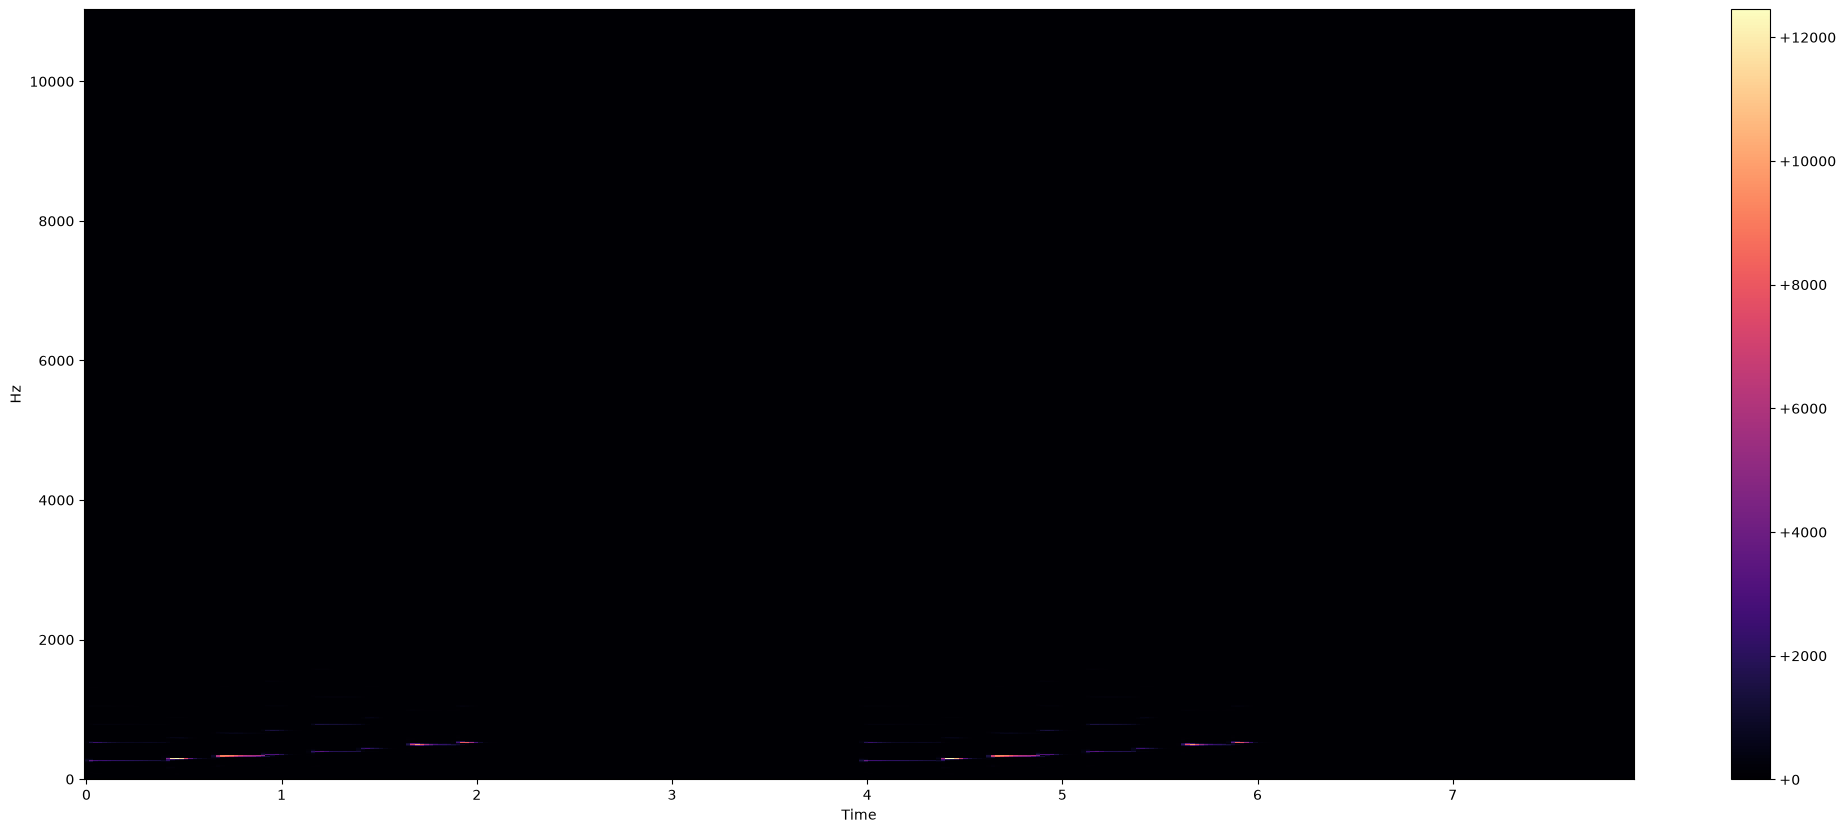

In [17]:
plot_spectrogram(Y_scale, sr, HOP_SIZE)

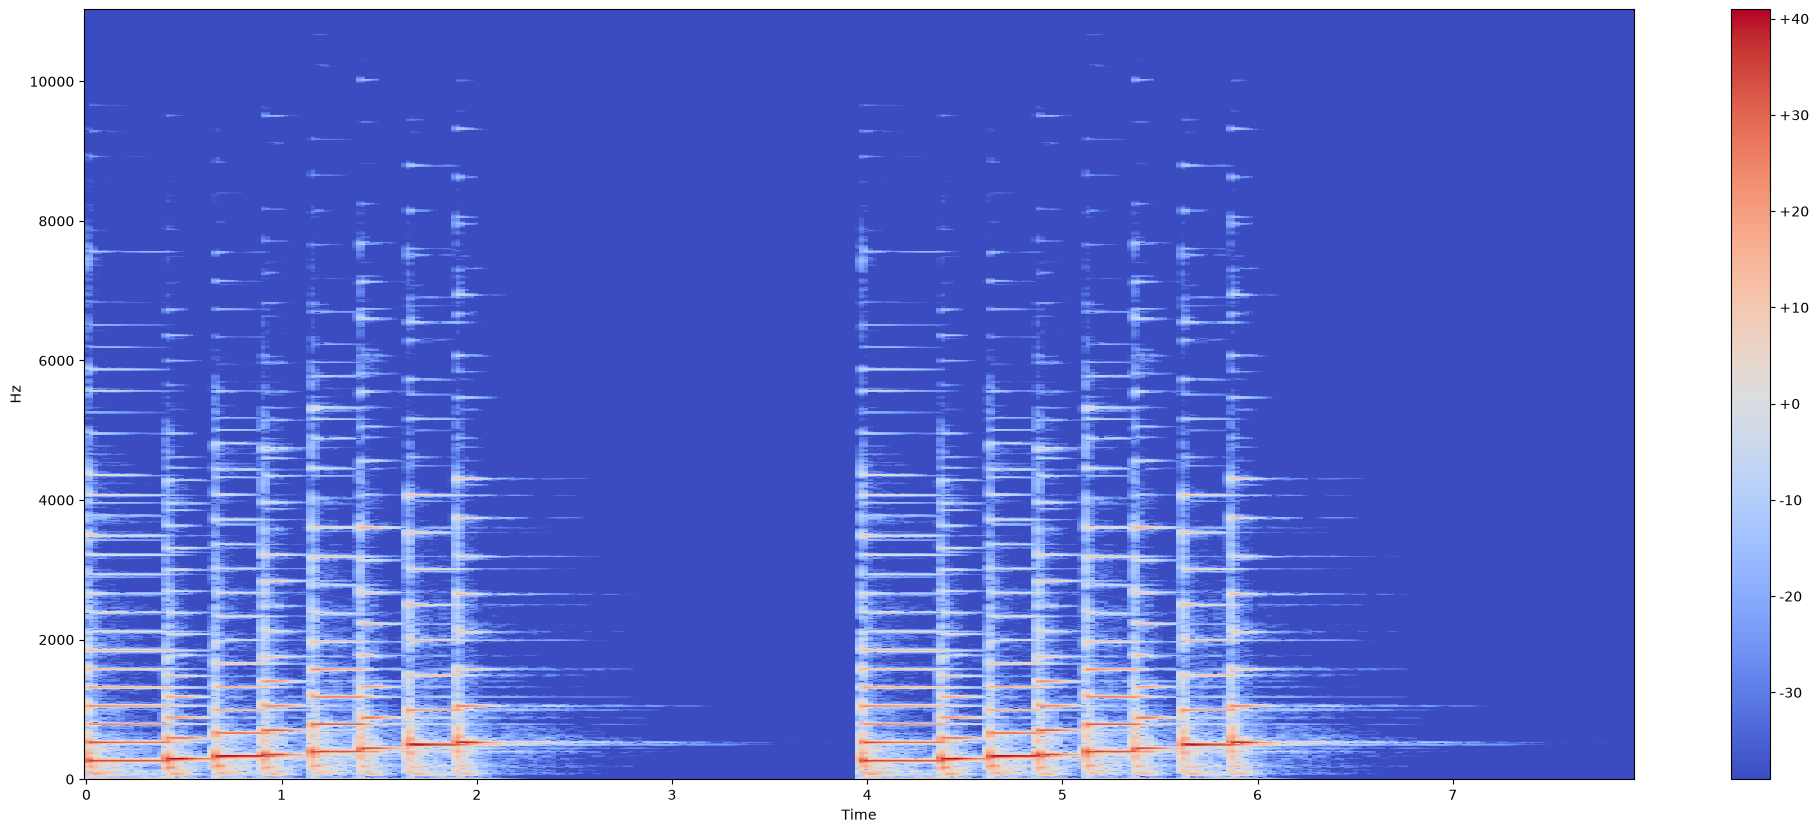

In [18]:
# TO LOG-AMPLITUDE SPECTROGRAM

Y_log_scale = librosa.power_to_db(Y_scale)
plot_spectrogram(Y_log_scale, sr, HOP_SIZE)

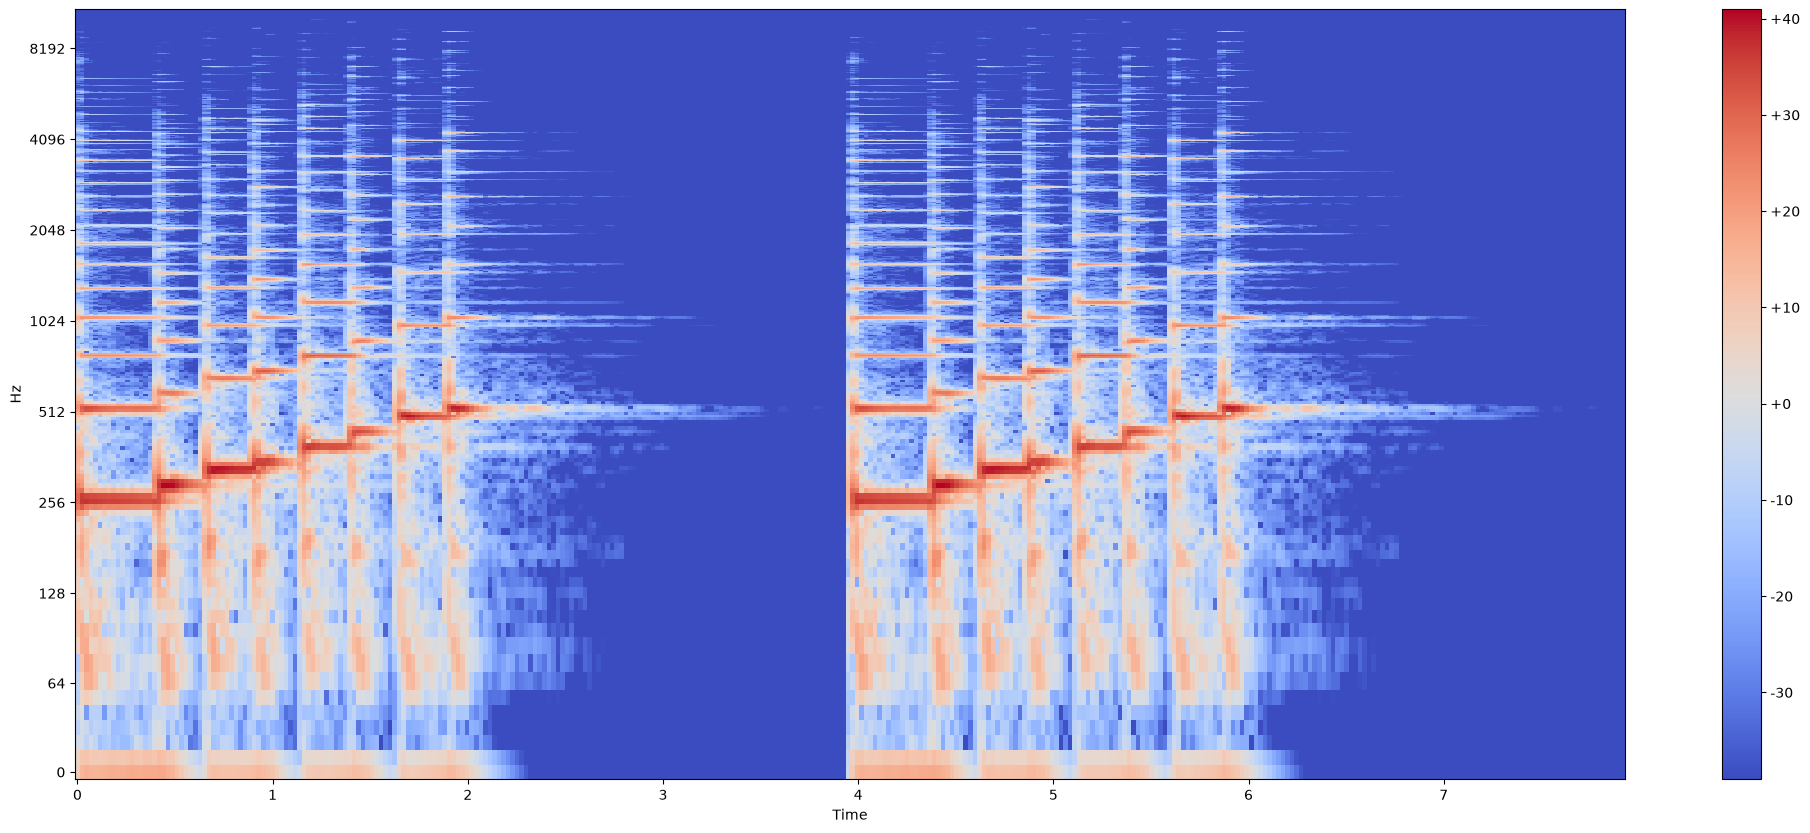

In [20]:
plot_spectrogram(Y_log_scale, sr, HOP_SIZE, y_axis="log")

In [23]:
def spectrogram(signal, sr, frame_size, hop_length, y_axis="log"):
    S_signal = librosa.stft(signal, n_fft=frame_size, hop_length=hop_length)
    Y_signal = librosa.power_to_db(np.abs(S_signal)**2)
    plot_spectrogram(Y_signal, sr, hop_length, y_axis)

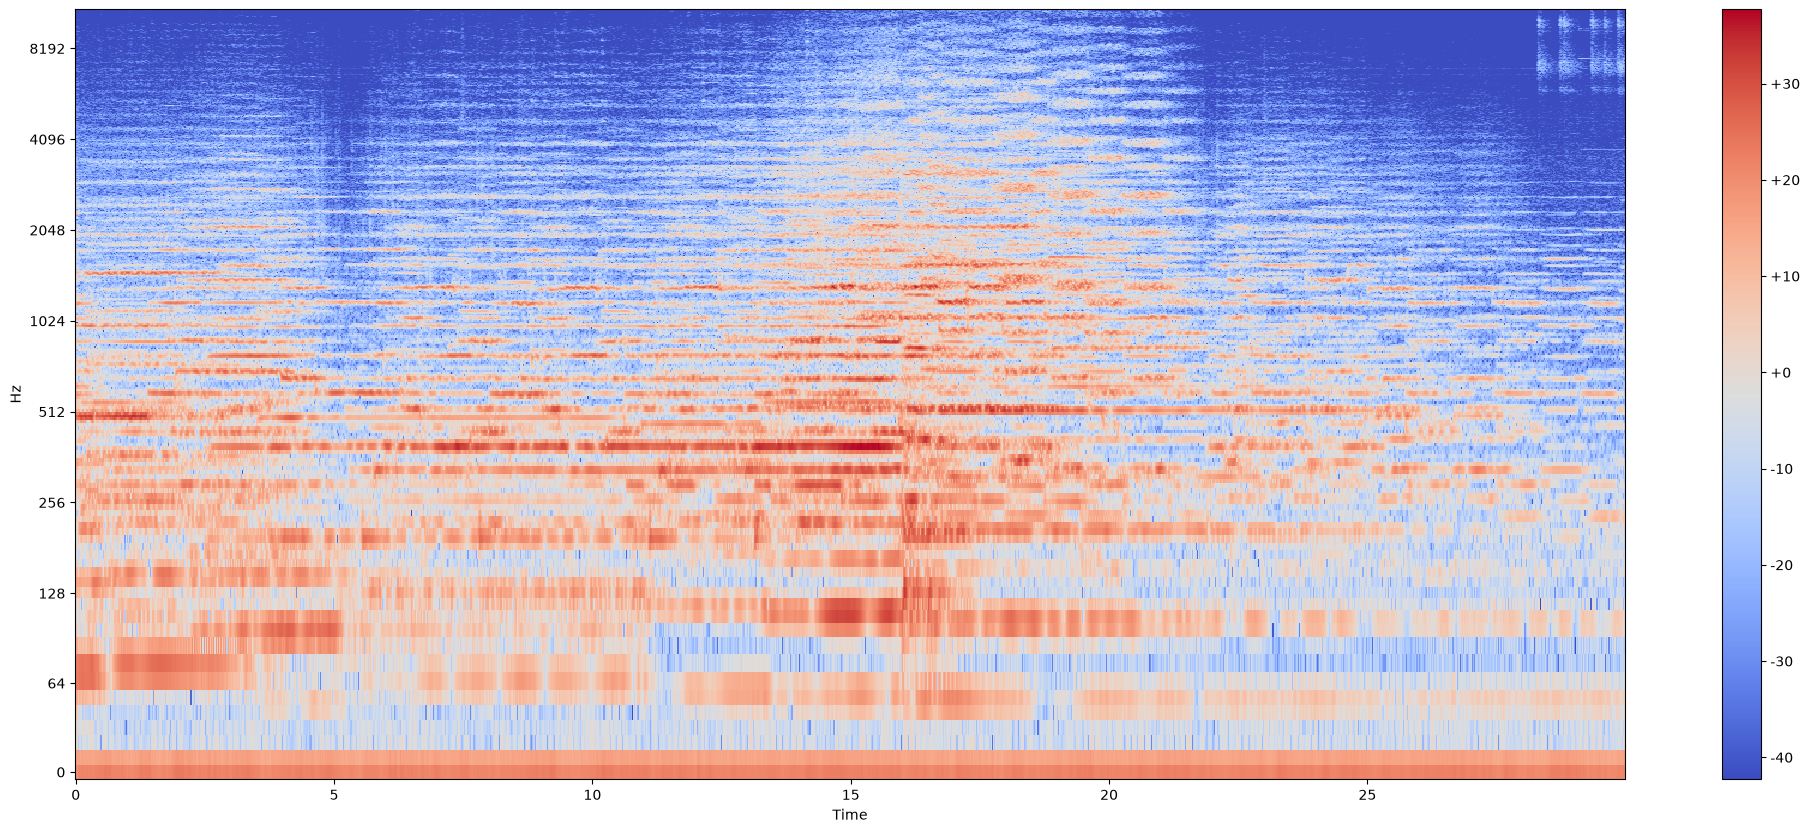

In [24]:
spectrogram(deb, sr, FRAME_SIZE, HOP_SIZE)

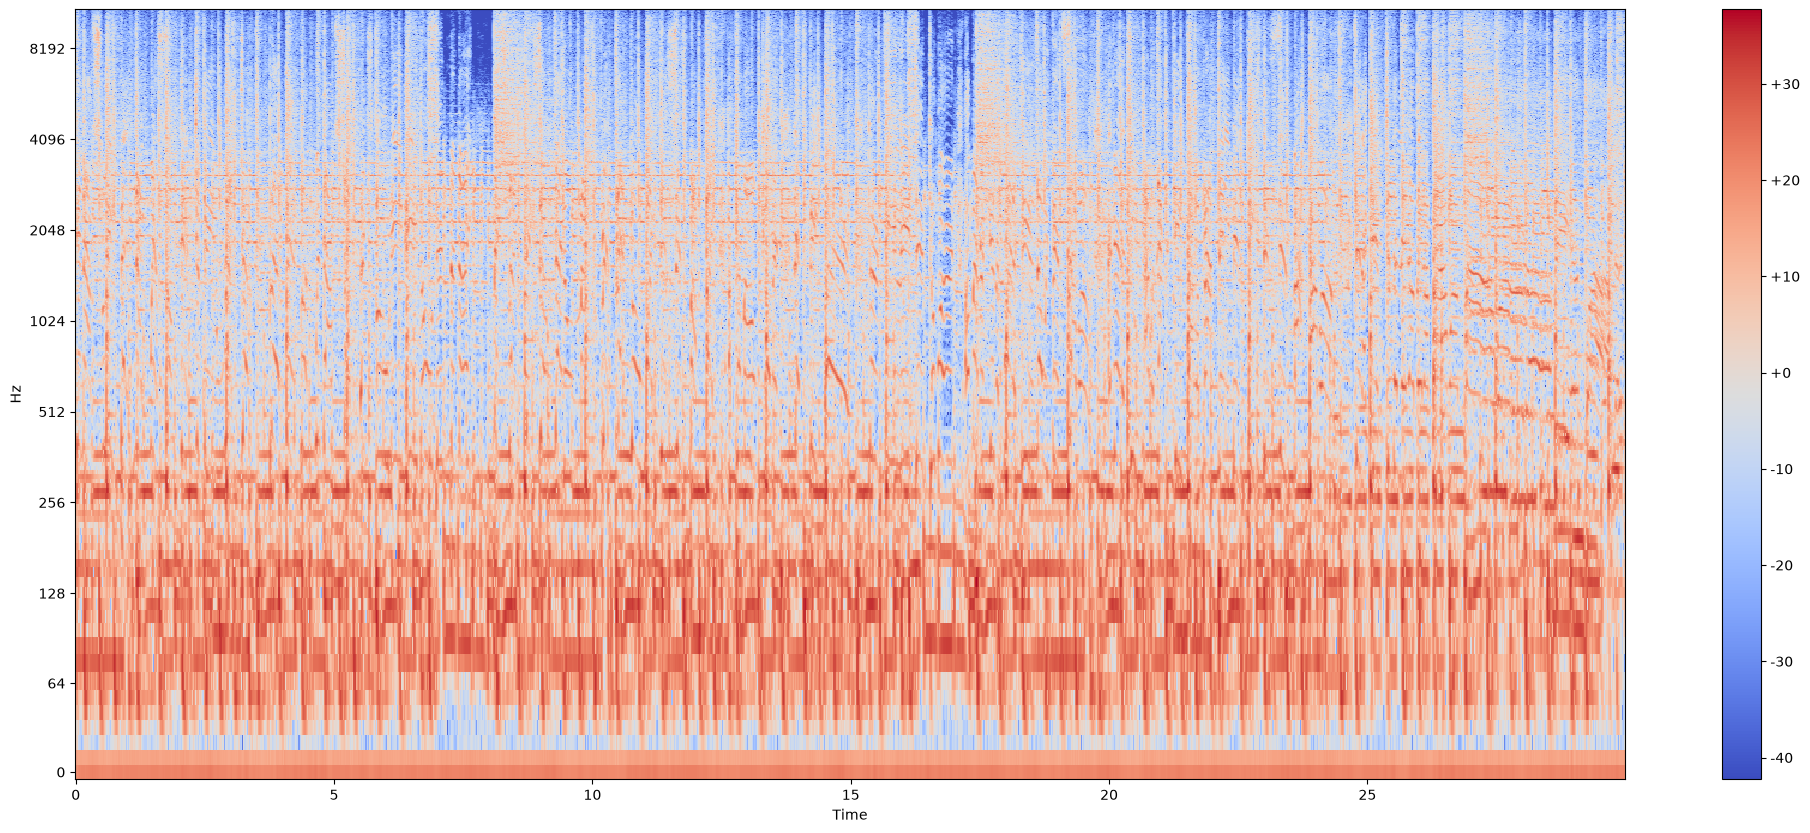

In [25]:
spectrogram(red, sr, FRAME_SIZE, HOP_SIZE)


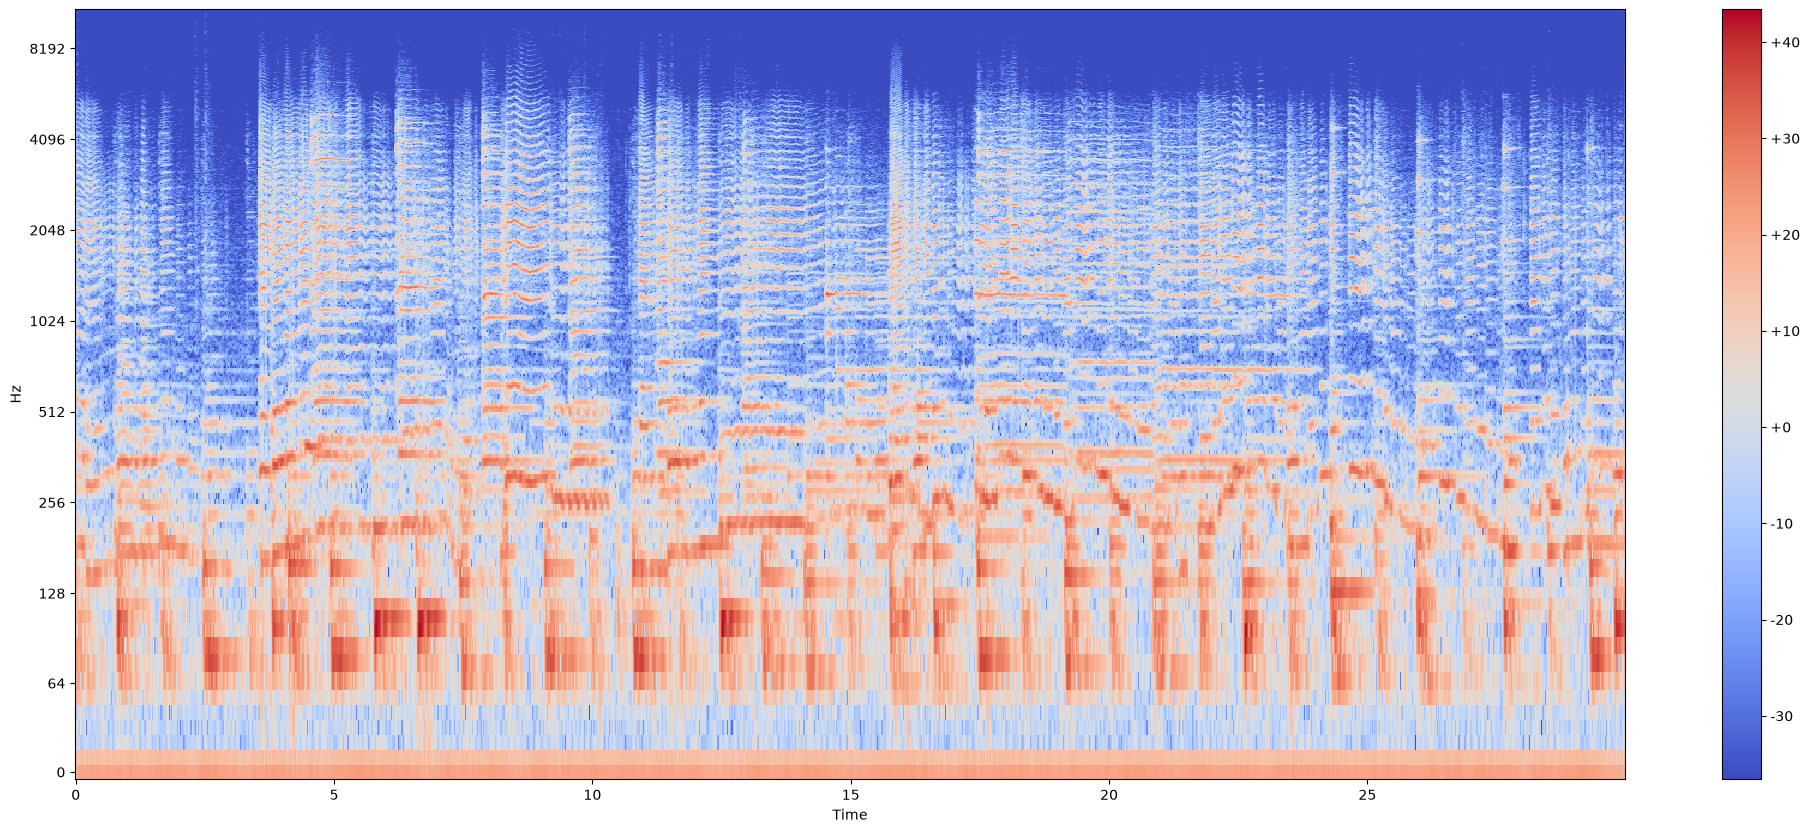

In [26]:
spectrogram(duk, sr, FRAME_SIZE, HOP_SIZE)